# 3 · Application: climate and mobility by zone

Use **xvec** to turn a half-month **FAPAR** cube into **zones** (one value per spatial-unit polygon and half-month), aggregate **mobility** to the same zones and half-months, and compare the two with the repository's plotting module `adaptive_cube_plot`. Both are converted to **z-scores**, so one color scale and one y-axis mean the same thing for climate and mobility.

| Step | Result |
|---|---|
| Load cube and spatial units | FAPAR cube from 2011, polygons with `norm_id` |
| `xvec.zonal_stats` | A vector data cube: one FAPAR mean per zone and half-month |
| `plot_zonal_maps`, `plot_zonal_timeseries` | Climate-only zonal maps and time series |
| `build_zonal_mobility` | Mobility on the same zones and time axis (starts later than the climate record) |
| `standardize_zonal` | Climate and mobility as z-scores over their common period |
| `plot_climate_mobility_maps` | Climate row and mobility row for the same dates in one panel |
| `plot_climate_mobility_timeseries` | One row per selected zone, both series, full climate record |

**Assumptions:** the cube has `time`, `lat`, and `lon` coordinates in EPSG:4326 with one time step per half-month; spatial units are polygons with a unique `norm_id` that matches the mobility origin IDs. The plotting module lives in `code/plot_utils/adaptive_cube_plot.py` and needs Cartopy for maps. Sections 5-8 run only if the mobility file exists (`RUN_MOBILITY`).

> Start with a short time window if exact extraction is slow. `exactextract` uses fractional pixel coverage; the fallback `rasterize` method is faster but may omit small polygons. xvec requires the geometries and raster coordinates to use the same CRS. [xvec zonal statistics documentation](https://xvec.readthedocs.io/en/latest/generated/xarray.DataArray.xvec.zonal_stats.html).

## 1 · Load the cube and zone polygons

This cell opens one Zarr store, reads the spatial-unit Parquet file, and limits processing to the cube footprint. If needed, set `START_DATE` and `END_DATE` to a smaller pilot period before extracting.

In [20]:
from pathlib import Path
import sys

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr
import xvec  # registers the .xvec accessor
import rioxarray  # needed by the exactextract backend
from shapely.geometry import box

# Find the repository root from the current notebook directory.
REPO = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
            if (p / "pyproject.toml").exists())
DATA = REPO / "data"

# Plot helpers from this repository: code/plot_utils/adaptive_cube_plot.py
sys.path.insert(0, str(REPO / "code" / "plot_utils"))
from adaptive_cube_plot import (
    build_zonal_mobility, common_period, plot_climate_mobility_maps,
    plot_climate_mobility_timeseries, plot_spatial_timeseries, plot_zonal_maps,
    plot_zonal_timeseries, standardize_zonal,
)
MAP_CONTEXT = True  # coastlines/borders on maps; Natural Earth data is downloaded on first use
PRODUCT = "METREF"  # half-month product; must match the Zarr data variable
ZONE_FILE = DATA / "aoi" / "spatial_units_with_lat_lon.parquet"
START_DATE = None  # e.g. "2013-01-01"; None means all available dates
END_DATE = None    # e.g. "2015-12-31"

stores = sorted(p for p in (DATA / "zarr").glob("*.zarr") if (p / "zarr.json").exists())
if not stores:
    raise FileNotFoundError("No Zarr v3 store found under data/zarr; build the cube first.")
store = next((p for p in stores if PRODUCT.lower() in p.name.lower()), stores[0])
ds = xr.open_zarr(store, consolidated=False)
if PRODUCT not in ds:
    raise KeyError(f"{PRODUCT!r} not in {list(ds.data_vars)}")

# Standardize common coordinate names if this cube uses other names.
rename = {old: new for old, new in {"latitude": "lat", "longitude": "lon",
                                    "y": "lat", "x": "lon"}.items()
          if old in ds.dims or old in ds.coords}
ds = ds.rename(rename)
required = {"time", "lat", "lon"}
if not required.issubset(ds[PRODUCT].dims):
    raise ValueError(f"Expected {required} dimensions; found {ds[PRODUCT].dims}")

# Read polygon geometries from WKB Parquet (as in this tutorial's input data).
units_df = pd.read_parquet(ZONE_FILE)
if "geometry" in units_df and len(units_df) and isinstance(units_df.geometry.iloc[0], (bytes, bytearray, memoryview)):
    import shapely
    geometry = shapely.from_wkb(units_df.pop("geometry").to_numpy())
    units = gpd.GeoDataFrame(units_df, geometry=geometry, crs="EPSG:4326")
else:
    units = gpd.GeoDataFrame(units_df, geometry="geometry", crs="EPSG:4326")
if units.crs is None:
    raise ValueError("Spatial-unit CRS is missing; set the correct CRS before continuing.")
units = units.to_crs("EPSG:4326")
if "norm_id" not in units or units["norm_id"].duplicated().any():
    raise ValueError("Spatial units need a unique 'norm_id' column.")

# Trim to the time window before zonal extraction to keep the pilot manageable.
da = ds[PRODUCT].sel(time=slice(START_DATE, END_DATE))
if da.sizes.get("time", 0) == 0:
    raise ValueError("No time steps in the requested date range.")
# Include half a cell around the outer coordinate centers when selecting zones.
dx = float(np.median(np.abs(np.diff(ds.lon.values))))
dy = float(np.median(np.abs(np.diff(ds.lat.values))))
cube_footprint = box(float(ds.lon.min())-2*dx, float(ds.lat.min())-dy/2,
                     float(ds.lon.max())+2*dx, float(ds.lat.max())+dy/2)
units_in = units.loc[units.geometry.intersects(cube_footprint)].copy()
if units_in.empty:
    raise ValueError("No spatial units intersect the cube extent.")
print(f"Store: {store.name} | {dict(ds.sizes)}")
print(f"Zones intersecting cube: {len(units_in)} / {len(units)}")
print(f"Period: {pd.Timestamp(da.time.values[0]).date()} to {pd.Timestamp(da.time.values[-1]).date()}")

Store: metref_sample_1month.zarr | {'time': 30, 'lat': 91, 'lon': 121}
Zones intersecting cube: 151 / 151
Period: 2020-06-01 to 2020-06-30


## 2 · Create zones with xvec

The spatial units become the **zones**. We pass the polygons to xvec once and ask for a spatial mean. The result is a *vector data cube*: the raster dimensions `lat`/`lon` are replaced by one `zone` dimension whose index holds the polygon geometries, and `time` is kept. The zone ID `norm_id` stays attached as a coordinate, so results can be joined back to other tables.

`exactextract` is preferred for fractional pixel coverage. If it is unavailable, the cell uses `rasterize` and reports that choice. With the fallback, cells are assigned by their centers (`all_touched=False`); small zones can have no cells, so inspect missing values.

The cube is passed to xvec with `x`/`y` dimension names, because the `exactextract` backend looks for those spatial dimension names.

In [21]:
# xvec needs matching CRS. This cube's lon/lat coordinates and zones are EPSG:4326.
zone_geometries = units_in.set_index("norm_id").geometry
try:
    import exactextract  # noqa: F401
    ZONAL_METHOD = "exactextract"
except ImportError:
    ZONAL_METHOD = "rasterize"
# add count of pixels per zone, for reference as well in the stats table
stats = ["count", "mean", "median", "min", "max"]
zonal = da.rename(lon="x", lat="y").xvec.zonal_stats(
    geometry=zone_geometries,
    x_coords="x",
    y_coords="y",
    stats=stats,
    name="zone",
    index=True,
    method=ZONAL_METHOD,
    all_touched=False,
).rename("zonal_mean").load()

n_missing = int(zonal.isnull().all("time").sum())
# table for number of pixels per zone, for reference

print("xvec method:", ZONAL_METHOD)
print(f"Zones: {zonal.sizes['zone']} | time steps: {zonal.sizes['time']} | "
      f"zones with no value at any time: {n_missing}")
steps = pd.DatetimeIndex(zonal.time.values)
print(f"Time steps: {len(steps)} ({steps[0].date()} to {steps[-1].date()}), "
      f"median spacing {steps.to_series().diff().dt.days.median():.0f} days")
zonal

xvec method: exactextract
Zones: 151 | time steps: 30 | zones with no value at any time: 0
Time steps: 30 (2020-06-01 to 2020-06-30), median spacing 1 days


<xarray.DataArray 'zonal_mean' (zone: 151, zonal_statistics: 5, time: 30)> Size: 181kB
array([[[  3.97959895,   3.97959895,   3.97959895, ...,   3.97959895,
           3.97959895,   3.97959895],
        [  3.68635417,   5.04255386,   4.74717232, ...,   5.14019542,
           4.77937929,   5.1369814 ],
        [  3.67198968,   5.03999996,   4.74864817, ...,   5.13866663,
           4.74001026,   5.13960409],
        [  3.59000182,   5.01999998,   4.71000099, ...,   5.05000687,
           4.6700058 ,   5.05000019],
        [  3.87999034,   5.08999872,   4.77999878, ...,   5.21999931,
           5.05999994,   5.18999767]],

       [[ 87.52293712,  87.52293712,  87.52293712, ...,  87.52293712,
          87.52293712,  87.52293712],
        [  4.33556537,   5.36682851,   5.15239814, ...,   5.45758998,
           5.36384164,   5.3126017 ],
        [  4.3413496 ,   5.38000011,   5.19999695, ...,   5.45999956,
           5.39000177,   5.34999943],
        [  3.65004206,   5.10001659,   4.72004366, ...,   5.19002342,
           5.05002213,   4.91002083],
        [  4.75998783,   5.48000002,   5.26999521, ...,   5.55999947,
...
           4.70937339,   4.70937339],
        [  4.2015328 ,   4.59011289,   5.11560154, ...,   5.28094635,
           5.01268055,   4.76242862],
        [  4.25591993,   4.59932137,   5.09868813, ...,   5.28552389,
           4.99000216,   4.79015398],
        [  3.92001581,   4.51000357,   5.04999876, ...,   5.21000385,
           4.91000319,   4.63000679],
        [  4.55997515,   4.71999979,   5.16999578, ...,   5.29999924,
           5.08998585,   4.82999992]],

       [[  5.11965863,   5.11965863,   5.11965863, ...,   5.11965863,
           5.11965863,   5.11965863],
        [  2.7257812 ,   4.91610452,   4.91849446, ...,   4.97263442,
           5.06491742,   2.89939645],
        [  2.77371502,   4.90666676,   4.92210054, ...,   4.98479366,
           5.06467772,   2.85094595],
        [  2.48000026,   4.71000385,   4.75000572, ...,   4.82000589,
           4.9400053 ,   2.68001032],
        [  2.92999721,   4.98000002,   4.98999834, ...,   4.99999762,
           5.1499939 ,   3.55997562]]], shape=(151, 5, 30))
Coordinates:
  * zone              (zone) geometry 1kB MULTIPOLYGON (((-17.1400547 14.5782...
    norm_id           (zone) object 1kB 'sen.1.1.1' 'sen.10.1.1' ... 'city-054'
  * zonal_statistics  (zonal_statistics) <U6 120B 'count' 'mean' ... 'min' 'max'
  * time              (time) datetime64[ns] 240B 2020-06-01 ... 2020-06-30
Indexes:
    zone     GeometryIndex (crs=EPSG:4326)
Attributes:
    long_name:  METREF
    units:      mm/day

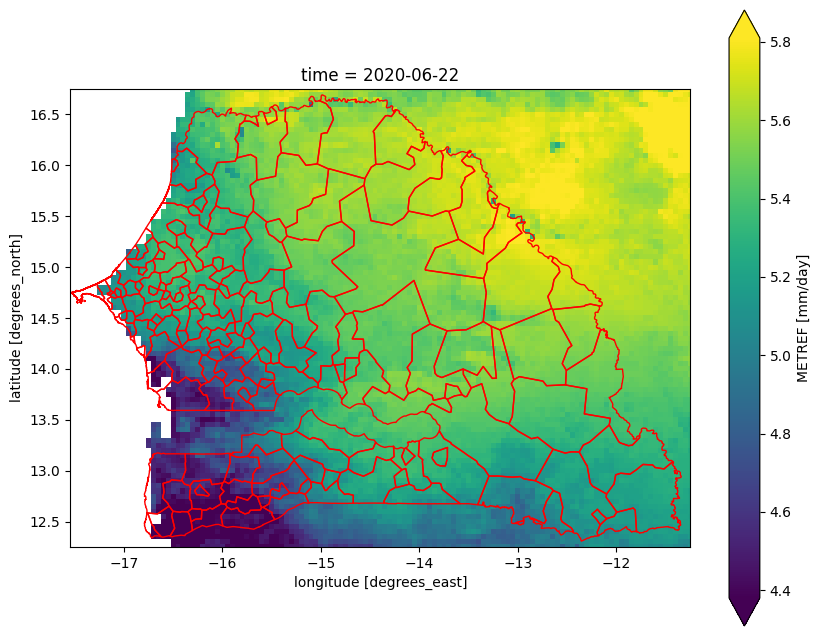

In [30]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 8))

da.isel(time=21).plot(
    ax=ax,
    x="lon",
    y="lat",
    cmap="viridis",
    robust=True,
)

units_in.boundary.plot(
    ax=ax,
    color="red",
    linewidth=1,
)

xmin, ymin, xmax, ymax = units_in.total_bounds
ax.set_xlim(min(xmin, float(da.lon.min())), max(xmax, float(da.lon.max())))
ax.set_ylim(min(ymin, float(da.lat.min())), max(ymax, float(da.lat.max())))

plt.show()

In [6]:
zonal.sel(zonal_statistics="count")

<xarray.DataArray 'zonal_mean' (zone: 151, time: 30)> Size: 36kB
array([[  3.97959895,   3.97959895,   3.97959895, ...,   3.97959895,
          3.97959895,   3.97959895],
       [ 87.52293712,  87.52293712,  87.52293712, ...,  87.52293712,
         87.52293712,  87.52293712],
       [105.31437333, 105.31437333, 105.31437333, ..., 105.31437333,
        105.31437333, 105.31437333],
       ...,
       [ 16.19736492,  16.19736492,  16.19736492, ...,  16.19736492,
         16.19736492,  16.19736492],
       [  4.70937339,   4.70937339,   4.70937339, ...,   4.70937339,
          4.70937339,   4.70937339],
       [  5.11965863,   5.11965863,   5.11965863, ...,   5.11965863,
          5.11965863,   5.11965863]], shape=(151, 30))
Coordinates:
  * zone              (zone) geometry 1kB MULTIPOLYGON (((-17.1400547 14.5782...
    norm_id           (zone) object 1kB 'sen.1.1.1' 'sen.10.1.1' ... 'city-054'
  * time              (time) datetime64[ns] 240B 2020-06-01 ... 2020-06-30
    zonal_statistics  <U6 24B 'count'
Indexes:
    zone     GeometryIndex (crs=EPSG:4326)
Attributes:
    long_name:  METREF
    units:      mm/day

## 3 · Climate zonal maps for a few time slices

`plot_zonal_maps` draws the zonal cube straight from xvec: polygons come from the `zone` geometry index, so no join back to a table is needed. One time index gives a single map; several give a panel. Panels share one color scale and one colorbar, use the module's `VAR_CMAP`, and are drawn in a local Cartopy projection. Zones without a value are hatched grey.

Choose the time slices with `N_SLICES` (evenly spaced over the period) or set `DATES` to your own list; dates are matched to the nearest available time step.

In [33]:
UNITS = da.attrs.get("units", "units not recorded")
LABEL = f"{PRODUCT} zonal mean"
N_SLICES = 4        # evenly spaced time slices over the period
DATES = None        # or e.g. ["2020-06-01", "2020-06-15", "2020-06-30"]
PANEL_COLS = 2

if DATES is None:
    SLICE_IDX = sorted(set(np.linspace(0, zonal.sizes["time"] - 1, N_SLICES).round().astype(int).tolist()))
else:
    SLICE_IDX = sorted(set(pd.Index(zonal.time.values).get_indexer(pd.to_datetime(DATES), method="nearest").tolist()))
print("Time slices:", ", ".join(str(pd.Timestamp(zonal.time.values[i]).date()) for i in SLICE_IDX))

Time slices: 2020-06-01, 2020-06-11, 2020-06-20, 2020-06-30


### Single zonal map

Each polygon is colored by the mean of the selected climate variable across its included cells. This is a **zonal summary**, not a higher-resolution map of the original raster.

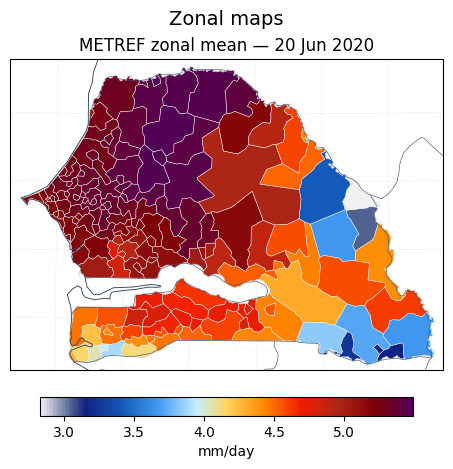

In [37]:
fig, axes = plot_zonal_maps(
    zonal.sel(zonal_statistics="mean"), var=LABEL, time_index=SLICE_IDX[len(SLICE_IDX) // 2],
    add_coastlines=MAP_CONTEXT, add_borders=MAP_CONTEXT,)

### Several time slices in one panel

The same function with all selected time indices. Use a few dates to inspect change; plotting every daily date would make an unwieldy figure. Pass `vmin`/`vmax` for fixed limits, or `robust=True` to clip the scale at the 2nd and 98th percentile.

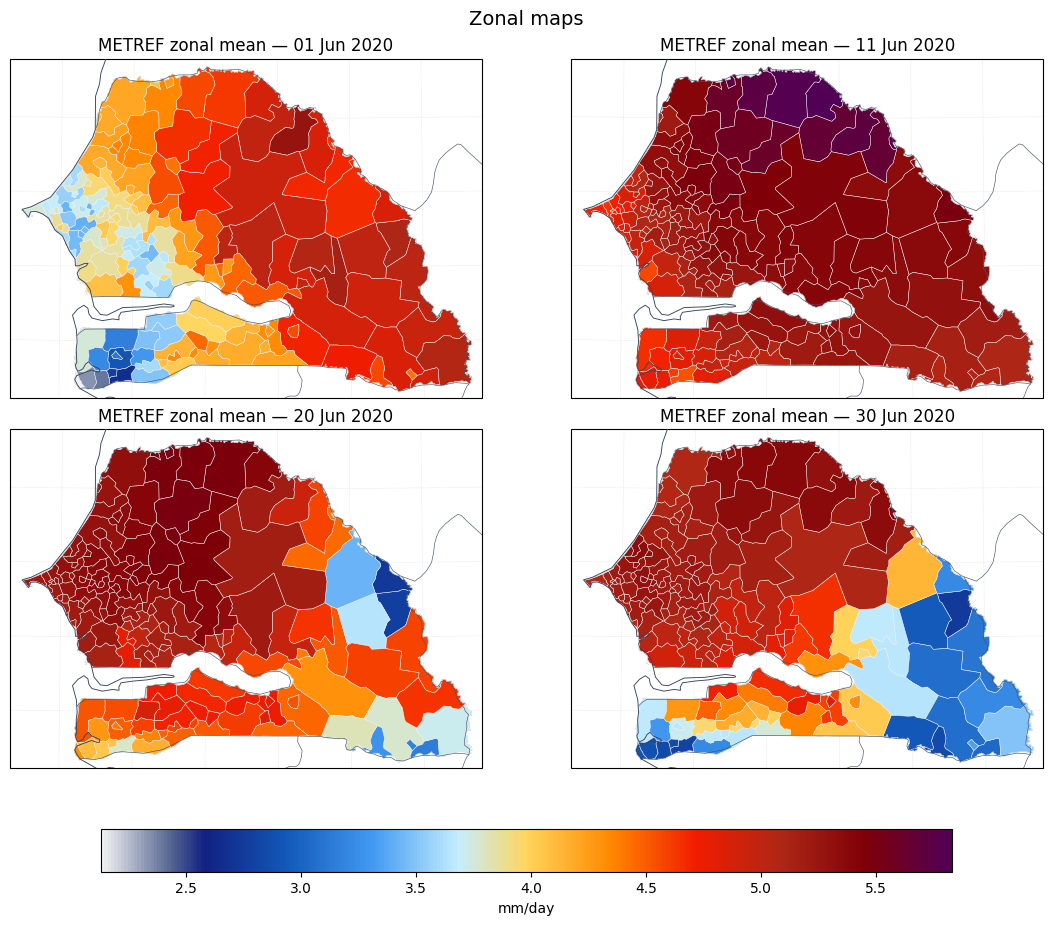

In [38]:
fig, axes = plot_zonal_maps(
    zonal.sel(zonal_statistics="median"), var=LABEL, time_index=SLICE_IDX, ncols=PANEL_COLS,
    add_coastlines=MAP_CONTEXT, add_borders=MAP_CONTEXT,
)

## 4 · Climate time series with a locator map

`plot_zonal_timeseries` plots the zonal mean through time for selected zones. A locator map shows where they are, in the same colors as the lines. By default it picks the zones with the lowest, median, and highest period mean; set `SELECTED_IDS` to your own `norm_id` values to override this. If the full period is long, first set `START_DATE` and `END_DATE` above to a suitable window.

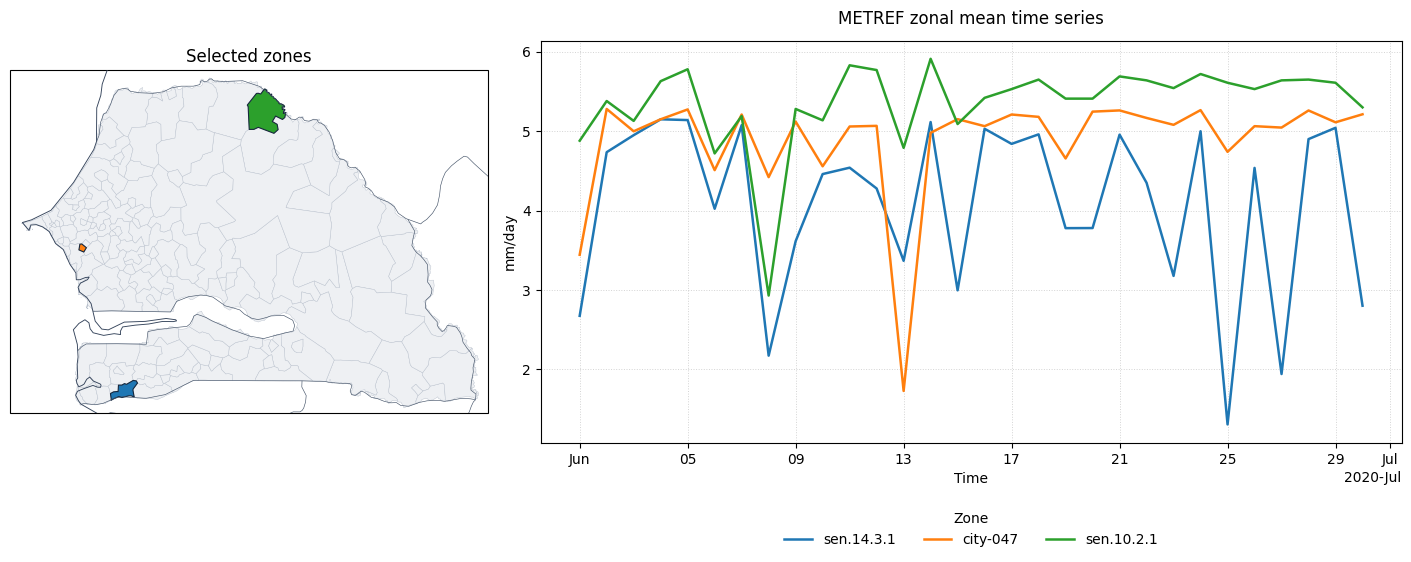

Zones: ['sen.14.3.1', 'city-047', 'sen.10.2.1']


In [40]:
SELECTED_IDS = None   # e.g. ["A12", "B07", "C03"]; None = lowest, median, highest period mean

fig, axes = plot_zonal_timeseries(
    zonal.sel(zonal_statistics="median"), var=LABEL, zones=SELECTED_IDS, id_coord="norm_id",
    add_coastlines=MAP_CONTEXT, add_borders=MAP_CONTEXT, title=f"{LABEL} time series",
)
SELECTED_IDS = axes["zones"]   # the zones that were plotted
print("Zones:", SELECTED_IDS)

### Optional: pixel-level check

`plot_spatial_timeseries` samples the raw cube at a point. Here it uses one point inside each selected zone, so you can compare a single pixel with the zonal mean above. The two should follow the same seasonal shape; a large offset means the zone mean is dominated by other pixels.

_id
sen.14.3.1    POINT (-16.11189 12.54367)
city-047      POINT (-16.71302 14.41597)
sen.10.2.1    POINT (-14.21085 16.25305)
dtype: geometry


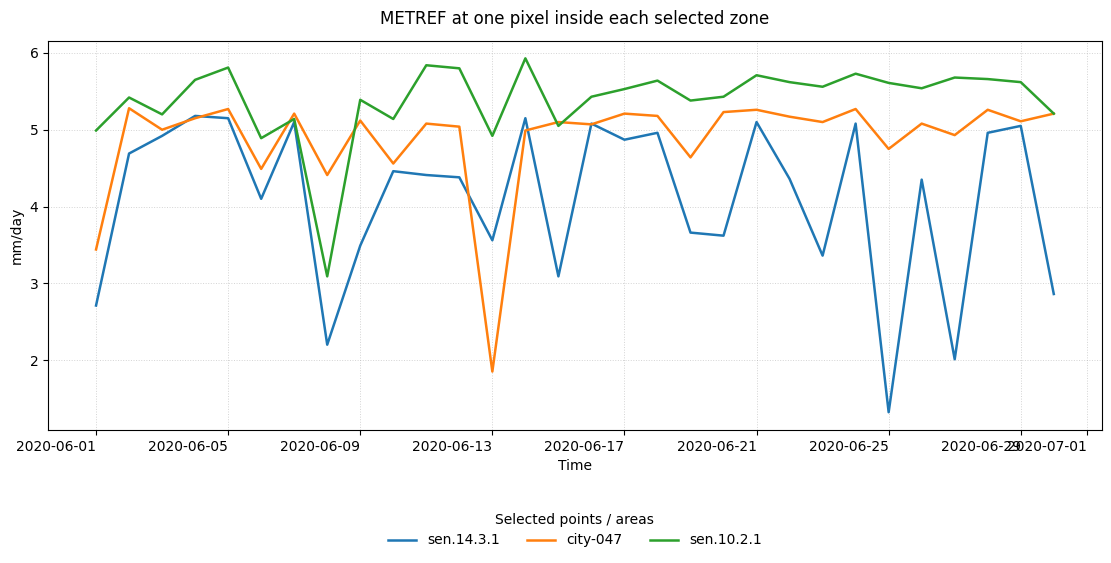

(<Figure size 1100x550 with 1 Axes>,
 <Axes: title={'center': 'METREF at one pixel inside each selected zone'}, xlabel='Time', ylabel='mm/day'>)

In [42]:
zone_points = (units_in.assign(_id=units_in["norm_id"].astype(str)).set_index("_id")
               .loc[SELECTED_IDS].geometry.representative_point())
print(zone_points)
plot_spatial_timeseries(
    da, points={zid: (pt.x, pt.y) for zid, pt in zone_points.items()},
    title=f"{PRODUCT} at one pixel inside each selected zone",
)

## 5 · Mobility on the same zones (optional)

`build_zonal_mobility` reads the mobility table (only the needed columns and filter rows from Parquet), sums the metric per origin zone and half-month, and returns a zone × time cube with **exactly the zones and time axis of the climate cube**. Half-months before the mobility record starts, and zones without records, are NaN. They are not set to zero, because a missing record is not a measured zero.

Then `common_period` finds the time range where both datasets have data. That overlap becomes the baseline for standardization, so both variables are scaled on the same years.

In [44]:
MOBILITY_FILE = DATA / "aoi" / "mobility_data_processed.parquet"
RUN_MOBILITY = MOBILITY_FILE.exists()      # sections 5-8 need the mobility file
METRIC = "rate_depart"
ID_COL, DATE_COL = "norm_spatial_id_origin", "date"
FILTERS = {"subset_type": "A", "weight_type": "unweighted", "days_span": "30days"}
AGG = "sum"                                # how rows in one zone and half-month are combined

if RUN_MOBILITY:
    MOB_LABEL = f"Mobility {METRIC}"
    mobility_zonal = build_zonal_mobility(
        MOBILITY_FILE, zonal.sel(zonal_statistics="median"), metric=METRIC, id_col=ID_COL, date_col=DATE_COL,
        filters=FILTERS, agg=AGG, id_coord="norm_id", name=MOB_LABEL,
    )
    has_mob = mobility_zonal.notnull().any("zone")
    first_mob = pd.Timestamp(mobility_zonal.time.values[has_mob.values][0]).date()
    BASELINE = common_period(zonal, mobility_zonal)
    print(f"Mobility zones with data: {int(mobility_zonal.notnull().any('time').sum())} / {mobility_zonal.sizes['zone']}")
    print(f"Mobility starts {first_mob}; climate starts {pd.Timestamp(zonal.time.values[0]).date()}")
    print(f"Common period (baseline): {BASELINE[0].date()} to {BASELINE[1].date()}")
else:
    print("Mobility file not found; skipping sections 5-8.")

ValueError: Several climate time steps fall in the same half-month; the cube must have one time step per half-month.

## 6 · Standardize to z-scores

A z-score says how many standard deviations a value is from the zone's own average, so FAPAR (a fraction) and mobility (a rate) can share one scale. With `STANDARDIZE = "time"`, each zone's mean and standard deviation are computed over the **common period only** and then applied to the whole record, so the 2011-2012 climate values sit on the same scale as everything after.

| Mode | Meaning |
|---|---|
| `"time"` | Per zone over time. Keeps the seasonal cycle, so both variables swing with the seasons |
| `"seasonal"` | Per zone and half-month of the year. Removes the seasonal cycle and shows anomalies; needs several years in the baseline |
| `"space"` | Across zones for each date. Shows which zones are high or low at that date, not change through time |

The cell also picks `N_SLICES` dates inside the common period for the maps.

In [ ]:
STANDARDIZE = "time"     # "time" | "seasonal" | "space"

if RUN_MOBILITY:
    climate_z = standardize_zonal(zonal, mode=STANDARDIZE, baseline=BASELINE)
    mobility_z = standardize_zonal(mobility_zonal, mode=STANDARDIZE, baseline=BASELINE)

    # Map dates inside the common period (both variables have data there).
    stamps = pd.DatetimeIndex(zonal.time.values)
    inside = np.flatnonzero((stamps >= BASELINE[0]) & (stamps <= BASELINE[1]))
    pick = np.linspace(0, inside.size - 1, N_SLICES).round().astype(int)
    OVERLAP_IDX = sorted(set(inside[pick].tolist()))
    print("Standardization:", climate_z.attrs["standardization"], "| baseline:", climate_z.attrs["baseline"])
    print("Map dates:", ", ".join(str(stamps[i].date()) for i in OVERLAP_IDX))

## 7 · Climate and mobility maps in one panel

Top row: FAPAR. Bottom row: mobility. Each column is one half-month. With z-scores both rows use the same diverging scale centered on 0 and one colorbar, so a red zone means "above its own average" in both rows. Hatched grey zones have no value, and a date without any mobility data (for example before the mobility record starts) shows a "no data" note.

### Single date

In [ ]:
if RUN_MOBILITY:
    fig, axes = plot_climate_mobility_maps(
        climate_z, mobility_z, time_index=OVERLAP_IDX[len(OVERLAP_IDX) // 2],
        climate_label=PRODUCT, mobility_label=MOB_LABEL,
        add_coastlines=MAP_CONTEXT, add_borders=MAP_CONTEXT,
    )

### Several dates

In [ ]:
if RUN_MOBILITY:
    fig, axes = plot_climate_mobility_maps(
        climate_z, mobility_z, time_index=OVERLAP_IDX,
        climate_label=PRODUCT, mobility_label=MOB_LABEL,
        add_coastlines=MAP_CONTEXT, add_borders=MAP_CONTEXT,
    )

## 8 · Climate and mobility time series per zone

One row per selected zone, with both series as z-scores on a shared axis and a locator map in matching colors. The time axis follows the **climate record**, so the FAPAR line starts in 2011 and the mobility line starts when its record starts. The grey band is the common period used for standardization. By default the zones with the lowest, median, and highest mobility are shown; set `COMPARE_IDS` to your own `norm_id` values to override this.

In [ ]:
COMPARE_IDS = None   # e.g. ["A12", "B07", "C03"]; None = lowest, median, highest mobility

if RUN_MOBILITY:
    fig, axes = plot_climate_mobility_timeseries(
        climate_z, mobility_z, zones=COMPARE_IDS, select="mobility_extremes", baseline=BASELINE,
        climate_label=PRODUCT, mobility_label=MOB_LABEL,
        add_coastlines=MAP_CONTEXT, add_borders=MAP_CONTEXT,
        title=f"{PRODUCT} and mobility as z-scores ({STANDARDIZE})",
    )
    COMPARE_IDS = axes["zones"]
    print("Zones:", COMPARE_IDS)

### Raw units

The same zones in their original units, with mobility on a second y-axis. Use this to read actual FAPAR and mobility values; the z-score figure above is the one to compare shapes and timing.

In [ ]:
if RUN_MOBILITY:
    fig, axes = plot_climate_mobility_timeseries(
        zonal, mobility_zonal, zones=COMPARE_IDS, baseline=BASELINE,
        climate_label=PRODUCT, mobility_label=MOB_LABEL,
        add_coastlines=MAP_CONTEXT, add_borders=MAP_CONTEXT,
        title=f"{PRODUCT} and mobility in original units",
    )

## Interpretation and checks

- **CRS:** xvec does not verify that polygon and raster CRSs match; this notebook explicitly reprojects zones to EPSG:4326. Confirm the cube coordinates really are longitude/latitude degrees.
- **Pixel support:** a zone smaller than a pixel, or with only a few pixels, has an unstable mean. Check the number of zones with no value (printed after extraction) and look for hatched grey zones on the maps.
- **Method choice:** `exactextract` accounts for fractional pixel coverage but adds a dependency and more work. `rasterize` is faster, but boundary assignment is approximate and very small polygons may return no value.
- **Half-month alignment:** climate and mobility dates are both mapped to the half-month that contains them (days 1-15 and 16-end). The climate cube must have one time step per half-month; `build_zonal_mobility` stops with an error otherwise. Check that the mobility `date` marks the same period as the FAPAR composite.
- **Different record lengths:** FAPAR starts in 2011 and mobility later, so mobility is NaN for the earlier half-months. Standardization uses the common period only, so the two variables are scaled on the same years; values before it are plotted on that same scale, but they are extrapolated from a different period.
- **Zero versus missing:** zones or periods without a mobility record are missing, not zero. Aggregating with `AGG = "sum"` is only meaningful for counts or rates that can be added; use `"mean"` otherwise.
- **Standardization choice:** a z-score keeps the shape of the series but not its unit. `"time"` keeps the seasonal cycle, so two seasonal series will look correlated even if they are unrelated; use `"seasonal"` to compare anomalies, which needs several baseline years. `"space"` answers a different question (differences between zones at one date).
- **Shared color scale:** the z-score scale is symmetric around 0 and sized to the 98th percentile of the selected values (at least ±1); pass `zlim` to `plot_climate_mobility_maps` for a fixed range.
- **Mobility:** co-occurrence is descriptive, not evidence that climate caused a movement. Check period alignment, missing zones, ID types (`norm_id` and the mobility origin ID must match as text), privacy safeguards, and the filter choices.
- **Scale:** test a short time window and a representative set of zones first. Process larger periods in time batches if memory, computation, or storage becomes limiting.